# Play analysis

Sessions of play from the Overlord's `activity.jsonl` (see `overlord/sessionlog.py`): a session starts
when the game leaves `passive` (any lever pull) and ends when it returns there.

Each session lands in one of three **tiers**:

- **real victory**: it reached `victory2`, the real ending (purple freed the spirits).
- **false victory**: it won game 1 (the three rounds, on to `party`) but never reached `victory2`.
  Kickouts are here: they won game 1 and then let the final time out.
- **neither**: it ran out of time in one of the three rounds.

**Outcome** is finer: the furthest phase reached, or *kicked out*, or *real victory*.

Times are Pacific (America/Los_Angeles). Every chart is also saved as a PNG for Slack, in
`field_logs/<time>/plots/`. Fetch fresh logs with `tools/overlord_restart.sh --fetch`.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.transforms import offset_copy
import numpy as np
import pandas as pd

# When the piece was open (Pacific): sessions that start in this window. It opened in the small
# hours of Friday night, and Sunday's party day ends 10 am Monday.
OPEN_FROM, OPEN_UNTIL = "2026-11-14 01:00", "2026-11-16 10:00"
LOG_DIR = None          # None: the newest field_logs/<time>/ that has an activity.jsonl

root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "CLAUDE.md").exists())
if LOG_DIR is None:
    LOG_DIR = max(p.parent for p in (root / "field_logs").glob("*/activity.jsonl"))
LOG_DIR = Path(LOG_DIR)
PLOTS = LOG_DIR / "plots"
PLOTS.mkdir(exist_ok=True)
print("reading", LOG_DIR / "activity.jsonl")

reading /Users/sam/git_repos/pulleys/field_logs/20261121-203050/activity.jsonl


## Style

In [2]:
INK, MUTED, RULE = "#1f2328", "#5f6368", "#d0d4d9"
plt.rcParams.update({
    "figure.figsize": (10, 4.6), "figure.dpi": 110, "figure.facecolor": "white",
    "savefig.dpi": 200, "savefig.bbox": "tight", "savefig.pad_inches": 0.25, "savefig.facecolor": "white",
    "font.size": 11, "text.color": INK,
    "axes.edgecolor": RULE, "axes.labelcolor": MUTED, "axes.labelsize": 11,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": "#eceef0", "grid.linewidth": 0.8,
    "axes.axisbelow": True,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelsize": 10, "ytick.labelsize": 10,
    "xtick.major.size": 0, "ytick.major.size": 0,
    "legend.frameon": False, "legend.fontsize": 10,
})

def header(ax, title, subtitle=None, legend=None):
    """A left-aligned title, a muted subtitle, then a one-row legend, all above the plot."""
    at = lambda pts: offset_copy(ax.transAxes, fig=ax.figure, y=pts, units="points")
    y = 8
    if legend:
        handles, labels = legend
        ax.legend(handles, labels, loc="lower left", bbox_to_anchor=(0, 1), bbox_transform=at(y),
                  ncols=len(labels), borderaxespad=0, borderpad=0, handlelength=1.1, handleheight=0.9,
                  columnspacing=1.6, handletextpad=0.5)
        y += 22
    if subtitle:
        ax.text(0, 1, subtitle, transform=at(y), ha="left", va="bottom", color=MUTED, fontsize=10.5)
        y += 18
    ax.set_title(title, loc="left", pad=y, fontsize=14, fontweight="bold", color=INK)

def save(fig, name):
    fig.savefig(PLOTS / f"{name}.png")

def swatch(color, **kw):
    return plt.Rectangle((0, 0), 1, 1, fc=color, ec="none", **kw)

def hour_label(h):
    h %= 24
    return {0: "midnight", 12: "noon"}.get(h, f"{h % 12} {'am' if h < 12 else 'pm'}")

## Build one row per session

In [3]:
# Phases in game order. diorama_unlocked is from the Nov 14-15 version of the game.
ROUNDS = ["easy_round", "medium_round", "hard_round"]               # game 1
ENDGAME = ["party", "diorama_unlocked", "final_wait", "final"]       # game 1 won
PHASES = ROUNDS + ENDGAME
OUTCOMES = PHASES + ["kicked out", "real victory"]

TIERS = ["real victory", "false victory", "neither"]   # best first: stacks build up from real victory
# "false victory" is winning game 1 (the party) without going on to the real one
# Checked with the dataviz palette validator: green and amber pass every check (CVD dE 16).
# The grey is a deliberately quiet neutral for the background tier.
TIER_COLOR = {"real victory": "#008300", "false victory": "#eda100", "neither": "#c4c9cf"}
KICKOUT_COLOR = "#e34948"
TIER_LEGEND = ([swatch(TIER_COLOR[t]) for t in TIERS], TIERS)

events = []
for line in (LOG_DIR / "activity.jsonl").read_text().splitlines():
    try:
        events.append(json.loads(line))
    except ValueError:
        pass   # a line damaged by a power cut

sessions, cur = [], None
for ev in events:
    e, t = ev["e"], ev["t"]
    if e == "start":
        cur = {"n": ev["n"], "start": t, "pulls": 0, "goal_pulls": 0,
               "states": [ev["state"]], "game1_at": None, "victory_at": None}
    elif cur is None:
        continue
    elif e == "pull":
        cur["pulls"] += 1
        cur["goal_pulls"] += ev.get("g") == "goal"
    elif e == "state":
        s = ev["s"]
        cur["states"].append(s)
        if (s in ENDGAME or s in ("victory2", "kickout")) and cur["game1_at"] is None:
            cur["game1_at"] = t
        if s == "victory2" and cur["victory_at"] is None:
            cur["victory_at"] = t
    elif e == "end":
        cur["end"], cur["why"] = t, ev["why"]
        sessions.append(cur)
        cur = None

def outcome(states):
    if "victory2" in states:
        return "real victory"
    if "kickout" in states:
        return "kicked out"
    reached = [PHASES.index(s) for s in states if s in PHASES]
    return PHASES[max(reached)] if reached else "easy_round"

def tier(o):
    if o == "real victory":
        return "real victory"
    return "neither" if o in ROUNDS else "false victory"

df = pd.DataFrame(sessions)
df["outcome"] = pd.Categorical(df["states"].map(outcome), OUTCOMES, ordered=True)
df["tier"] = pd.Categorical(df["outcome"].map(tier).astype(str), TIERS, ordered=True)
df["victory"] = df["tier"] == "real victory"
df["game1"] = df["tier"] != "neither"     # won game 1, whatever came after

def local_time(seconds):
    return pd.to_datetime(seconds, unit="s", utc=True).dt.tz_convert("America/Los_Angeles").dt.tz_localize(None)

df["start_dt"], df["end_dt"] = local_time(df["start"]), local_time(df["end"])
# Party days: Saturday runs 10 am Saturday to 10 am Sunday, and so on.
# `hour` counts from the party day's midnight: 1 am the next morning is hour 25.
DAY_STARTS_AT = 10
df["day"] = (df["start_dt"] - pd.Timedelta(hours=DAY_STARTS_AT)).dt.normalize()
df["hours_in"] = (df["start_dt"] - df["day"]).dt.total_seconds() / 3600
df["hour"] = df["hours_in"].astype(int)
df["minutes"] = (df["end"] - df["start"]) / 60
df["minutes_to_game1"] = (df["game1_at"] - df["start"]) / 60
df["minutes_to_victory"] = (df["victory_at"] - df["start"]) / 60

# A session that lasts hours is the game left mid-round, not play. Kept in the counts,
# left out of the duration plots.
STUCK_MINUTES = 60
df["stuck"] = df["minutes"] > STUCK_MINUTES

df = df[(df["start_dt"] >= OPEN_FROM) & (df["start_dt"] < OPEN_UNTIL)].reset_index(drop=True)
DAYS = sorted(df["day"].unique())
DAY_LABEL = {d: pd.Timestamp(d).strftime("%a %b %-d") for d in DAYS}
_open = pd.Timestamp(OPEN_FROM)
if _open > DAYS[0] + pd.Timedelta(hours=DAY_STARTS_AT):   # the first day only had its small hours
    DAY_LABEL[DAYS[0]] = pd.Timestamp(DAYS[0]).strftime("%a %b %-d") + f"\n(from {hour_label(_open.hour)})"
played = df[~df["stuck"]]

# The one line under every chart's title, so a chart pasted alone still says what it covers
SPAN = (f"Pulleys, {pd.Timestamp(OPEN_FROM):%a %b %-d} {hour_label(pd.Timestamp(OPEN_FROM).hour)}"
        f" to {pd.Timestamp(OPEN_UNTIL):%a %b %-d} {hour_label(pd.Timestamp(OPEN_UNTIL).hour)}")

print(f"{len(df)} sessions: {df['game1'].sum()} reached false victory (game 1) ({df['game1'].mean():.0%}), "
      f"{df['victory'].sum()} reached real victory ({df['victory'].mean():.0%})")
print(f"left out of durations (over {STUCK_MINUTES} min, the game left mid-round):")
print(df.loc[df["stuck"], ["n", "start_dt", "end_dt", "minutes", "outcome"]].assign(
    start_dt=lambda d: d["start_dt"].dt.floor("min"), end_dt=lambda d: d["end_dt"].dt.floor("min"),
    minutes=lambda d: d["minutes"].round()).to_string(index=False))
df.groupby("day").agg(sessions=("n", "size"), game1=("game1", "sum"), victory=("victory", "sum"),
                      game1_rate=("game1", "mean"), victory_rate=("victory", "mean"),
                      pulls=("pulls", "sum")).join(
    played.groupby("day")["minutes"].median().rename("median_min")
).rename(index=lambda d: DAY_LABEL[d].replace("\n", " ")).round(2)

321 sessions: 137 reached false victory (game 1) (43%), 100 reached real victory (31%)
left out of durations (over 60 min, the game left mid-round):
  n            start_dt              end_dt  minutes          outcome
 77 2026-11-14 03:43:00 2026-11-14 13:39:00    596.0 diorama_unlocked
241 2026-11-15 04:25:00 2026-11-15 17:17:00    773.0       easy_round


,sessions,game1,victory,game1_rate,victory_rate,pulls,median_min
day,,,,,,,
Fri Nov 13 (from 1 am),20,12,3,0.60,0.15,5555,4.78
Sat Nov 14,164,55,36,0.34,0.22,35905,2.77
Sun Nov 15,137,70,61,0.51,0.45,23476,2.72


## Time of day

Each bar is one session, from its start to its end, colored by tier. Each row is a party day,
10 am to 10 am the next morning.

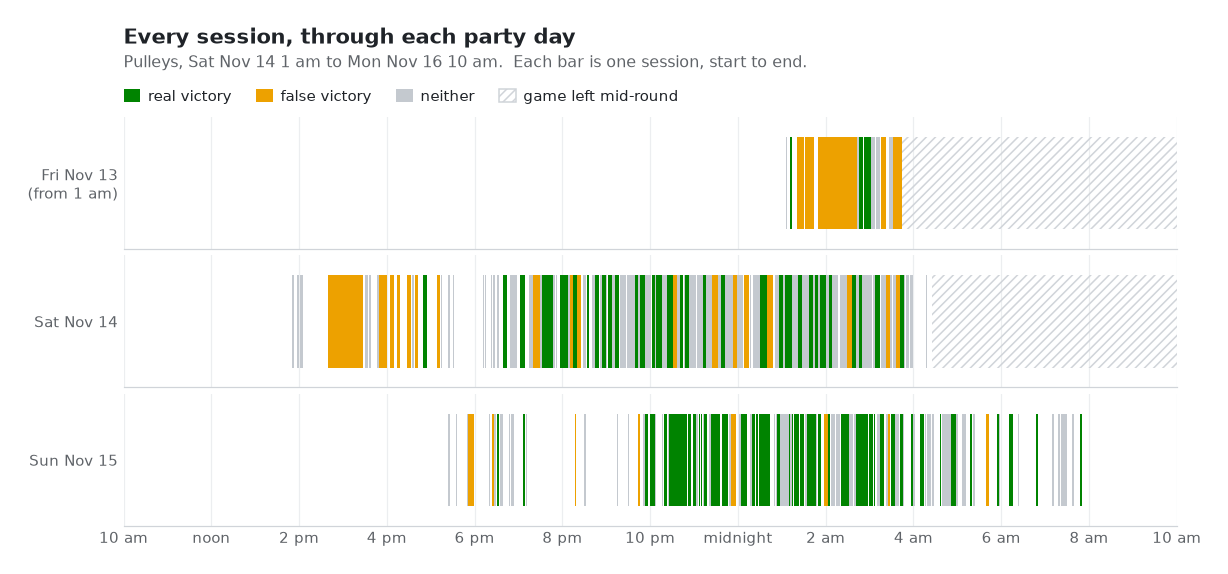

In [4]:
fig, axes = plt.subplots(len(DAYS), 1, figsize=(11, 1.15 * len(DAYS) + 1.6), sharex=True)
axes = np.atleast_1d(axes)
for ax, day in zip(axes, DAYS):
    base = pd.Timestamp(day)
    for _, s in df[df["day"] == day].iterrows():
        x0 = (s["start_dt"] - base).total_seconds() / 3600
        x1 = (s["end_dt"] - base).total_seconds() / 3600
        if s["stuck"]:
            ax.barh(0, x1 - x0, left=x0, height=0.7, fc="none", ec=RULE, hatch="////", lw=0)
        else:
            ax.barh(0, x1 - x0, left=x0, height=0.7, color=TIER_COLOR[s["tier"]], lw=0)
    ax.set_yticks([0], [DAY_LABEL[day]])
    ax.set_ylim(-0.5, 0.5)
    ax.grid(axis="x", color="#eceef0")
    ax.grid(axis="y", visible=False)
    ax.spines["left"].set_visible(False)
ticks = range(DAY_STARTS_AT, DAY_STARTS_AT + 25, 2)
axes[-1].set_xlim(DAY_STARTS_AT, DAY_STARTS_AT + 24)
axes[-1].set_xticks(ticks, [hour_label(h) for h in ticks])
header(axes[0], "Every session, through each party day", SPAN + ".  Each bar is one session, start to end.",
       ([*TIER_LEGEND[0], plt.Rectangle((0, 0), 1, 1, fc="none", ec=RULE, hatch="////")],
        [*TIER_LEGEND[1], "game left mid-round"]))
fig.tight_layout(h_pad=0.4)
save(fig, "01_timeline")

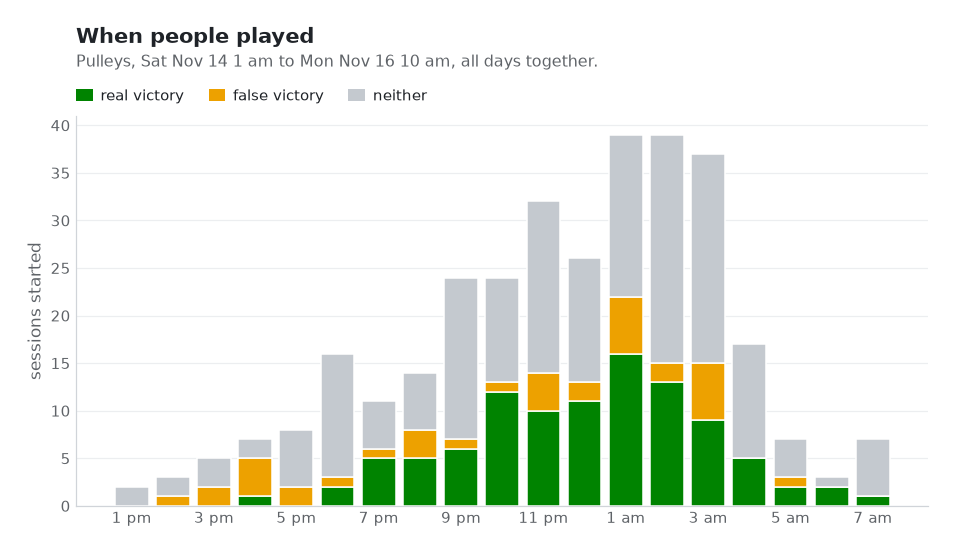

In [5]:
hours = range(df["hour"].min(), df["hour"].max() + 1)
by_hour = pd.crosstab(df["hour"], df["tier"]).reindex(index=hours, columns=TIERS, fill_value=0)
tick_hours = list(hours)[::2]

fig, ax = plt.subplots()
bottom = np.zeros(len(by_hour))
for t in TIERS:
    ax.bar(by_hour.index, by_hour[t], bottom=bottom, width=0.82, color=TIER_COLOR[t], ec="white", lw=1)
    bottom += by_hour[t].values
ax.set_xticks(tick_hours, [hour_label(h) for h in tick_hours])
ax.set_ylabel("sessions started")
header(ax, "When people played", SPAN + ", all days together.", TIER_LEGEND)
save(fig, "02_sessions_per_hour")

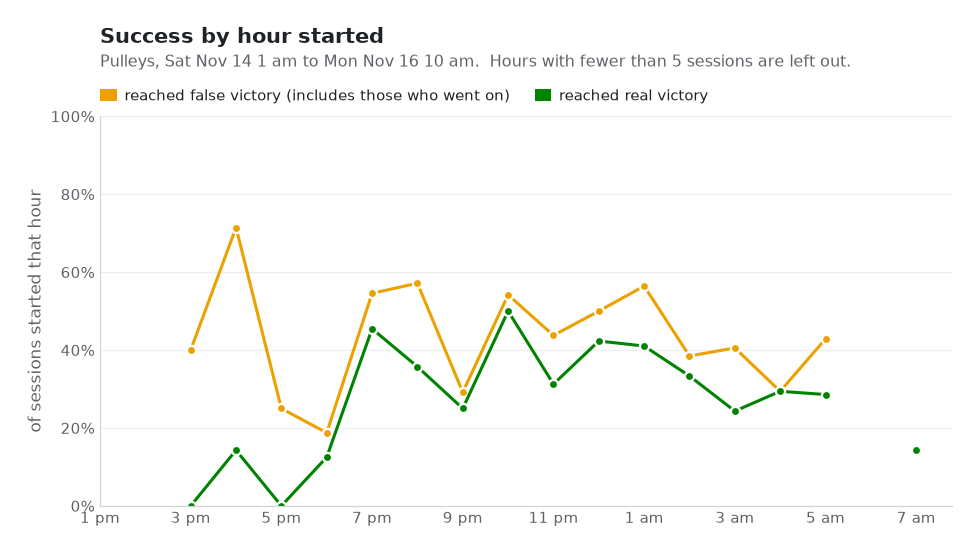

In [6]:
MIN_N = 5    # hours with fewer sessions than this are left off the rate chart
total = by_hour.sum(axis=1)
ok = total >= MIN_N
rates = {"false": (by_hour["real victory"] + by_hour["false victory"]) / total * 100,
         "real": by_hour["real victory"] / total * 100}

fig, ax = plt.subplots()
for name, color in [("false", TIER_COLOR["false victory"]), ("real", TIER_COLOR["real victory"])]:
    r = rates[name].where(ok)
    ax.plot(r.index, r, "-o", color=color, lw=2, ms=6, mec="white", mew=1.5)
ax.set_xticks(tick_hours, [hour_label(h) for h in tick_hours])
ax.set_ylim(0, 100)
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0f}%")
ax.set_ylabel("of sessions started that hour")
header(ax, "Success by hour started",
       f"{SPAN}.  Hours with fewer than {MIN_N} sessions are left out.",
       ([swatch(TIER_COLOR["false victory"]), swatch(TIER_COLOR["real victory"])],
        ["reached false victory (includes those who went on)", "reached real victory"]))
save(fig, "03_success_by_hour")

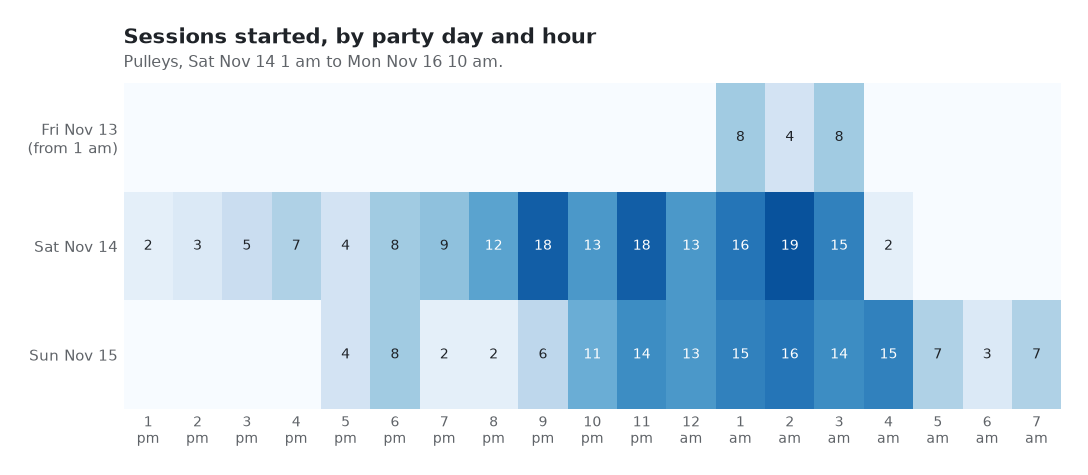

In [7]:
grid = df.pivot_table(index="day", columns="hour", values="n", aggfunc="size", fill_value=0) \
    .reindex(columns=hours, fill_value=0)
fig, ax = plt.subplots(figsize=(11, 0.75 * len(DAYS) + 1.6))
ax.imshow(grid, aspect="auto", cmap="Blues", vmin=0, vmax=grid.values.max() * 1.15)
ax.set_xticks(range(len(grid.columns)), [hour_label(h).replace("midnight", "12 am").replace("noon", "12 pm").replace(" ", "\n") for h in grid.columns], fontsize=9)
ax.set_yticks(range(len(grid.index)), [DAY_LABEL[d] for d in grid.index])
for (i, j), v in np.ndenumerate(grid.values):
    if v:
        ax.text(j, i, v, ha="center", va="center", fontsize=9,
                color="white" if v > grid.values.max() * 0.55 else INK)
ax.grid(False)
for s in ax.spines.values():
    s.set_visible(False)
header(ax, "Sessions started, by party day and hour", SPAN + ".")
save(fig, "04_heatmap")

## Play duration

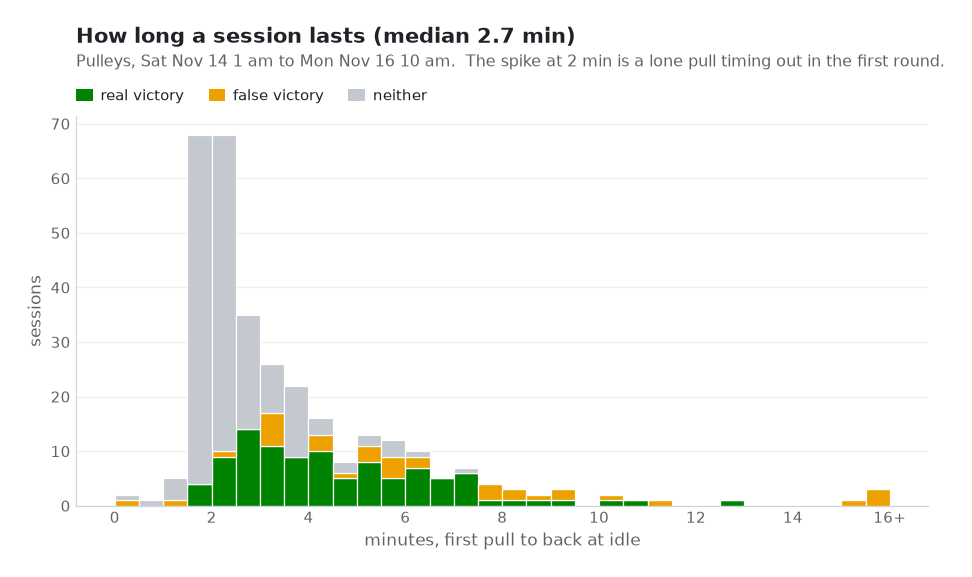

In [8]:
CAP = 16   # minutes (even, to match the 2-minute ticks); longer sessions go in the last bin
bins = np.arange(0, CAP + 0.5, 0.5)
clipped = played["minutes"].clip(upper=CAP - 0.01)

fig, ax = plt.subplots()
ax.hist([clipped[played["tier"] == t] for t in TIERS], bins=bins, stacked=True,
        color=[TIER_COLOR[t] for t in TIERS], ec="white", lw=0.8)
ax.set_xticks(range(0, CAP + 1, 2), [f"{m}" for m in range(0, CAP, 2)] + [f"{CAP}+"])
ax.set(xlabel="minutes, first pull to back at idle", ylabel="sessions")
header(ax, f"How long a session lasts (median {played['minutes'].median():.1f} min)",
       f"{SPAN}.  The spike at 2 min is a lone pull timing out in the first round.", TIER_LEGEND)
save(fig, "05_session_length")

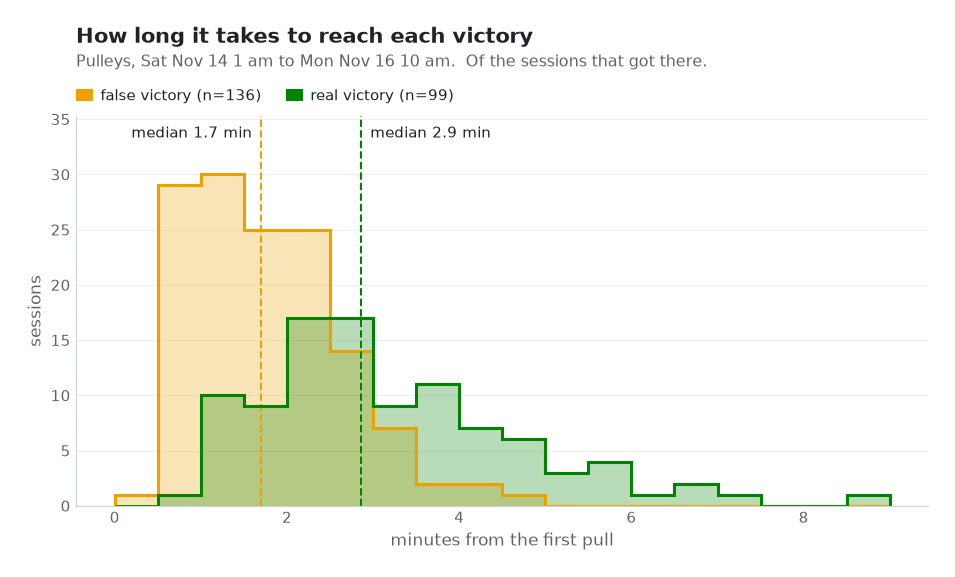

In [9]:
g1, v = df["minutes_to_game1"].dropna(), df["minutes_to_victory"].dropna()
bins = np.arange(0, max(g1.max(), v.max()) + 0.5, 0.5)

fig, ax = plt.subplots()
for data, t in [(g1, "false victory"), (v, "real victory")]:
    ax.hist(data, bins=bins, color=TIER_COLOR[t], alpha=0.28, lw=0)
    ax.hist(data, bins=bins, histtype="step", color=TIER_COLOR[t], lw=2)
    ax.axvline(data.median(), color=TIER_COLOR[t], ls="--", lw=1.3)
top = ax.get_ylim()[1] * 1.12   # headroom: the labels sit above the tallest bar
ax.set_ylim(0, top)
# false victory's label to the left of its line, real victory's to the right, so they never meet
for data, dx, ha in [(g1, -6, "right"), (v, 6, "left")]:
    ax.annotate(f"median {data.median():.1f} min", (data.median(), top), xytext=(dx, -14),
                textcoords="offset points", ha=ha, fontsize=10, color=INK)
ax.set(xlabel="minutes from the first pull", ylabel="sessions")
header(ax, "How long it takes to reach each victory",
       f"{SPAN}.  Of the sessions that got there.",
       ([swatch(TIER_COLOR["false victory"]), swatch(TIER_COLOR["real victory"])],
        [f"false victory (n={len(g1)})", f"real victory (n={len(v)})"]))
save(fig, "06_time_to_win")

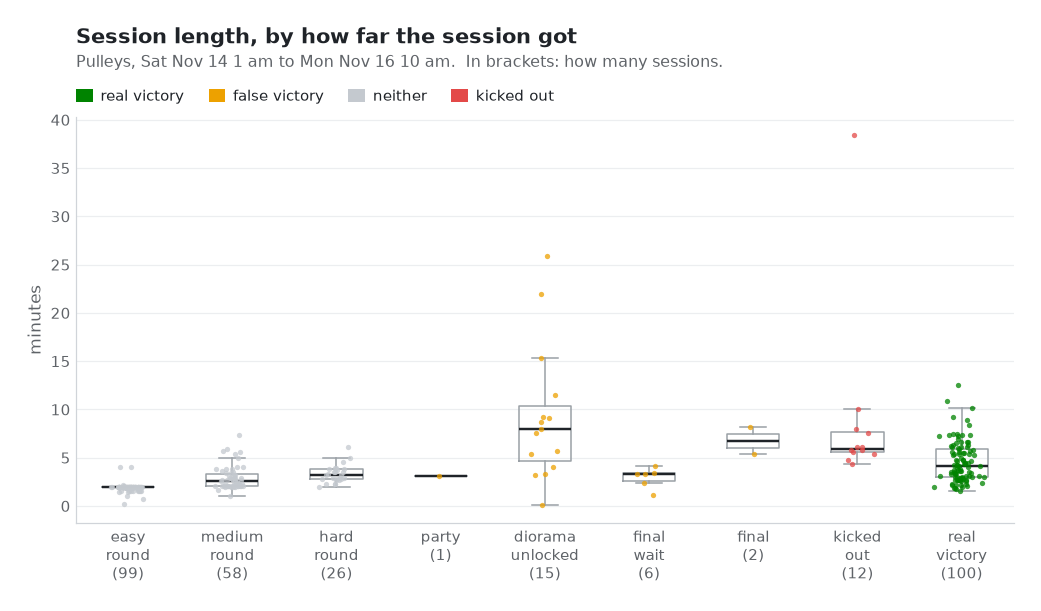

In [10]:
OUTCOME_COLOR = {o: TIER_COLOR[tier(o)] for o in OUTCOMES} | {"kicked out": KICKOUT_COLOR}
order = [o for o in OUTCOMES if (played["outcome"] == o).any()]
data = [played.loc[played["outcome"] == o, "minutes"] for o in order]
rng = np.random.default_rng(0)

fig, ax = plt.subplots(figsize=(11, 4.8))
ax.boxplot(data, widths=0.5, showfliers=False, medianprops={"color": INK, "lw": 1.6},
           boxprops={"color": "#9aa0a6"}, whiskerprops={"color": "#9aa0a6"}, capprops={"color": "#9aa0a6"})
for i, (o, d) in enumerate(zip(order, data), 1):
    ax.scatter(rng.normal(i, 0.07, len(d)), d, s=12, alpha=0.75, color=OUTCOME_COLOR[o], lw=0, zorder=3)
ax.set_xticks(range(1, len(order) + 1), [f"{o.replace('_', chr(10)).replace(' ', chr(10))}\n({len(d)})" for o, d in zip(order, data)])
ax.set_ylabel("minutes")
header(ax, "Session length, by how far the session got",
       f"{SPAN}.  In brackets: how many sessions.",
       ([*TIER_LEGEND[0], swatch(KICKOUT_COLOR)], [*TIER_LEGEND[1], "kicked out"]))
save(fig, "07_length_by_phase")

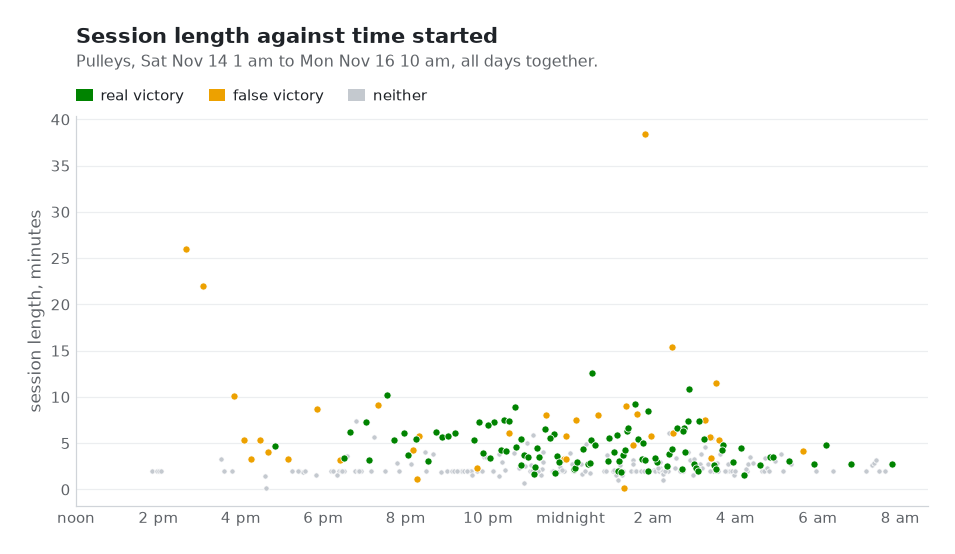

In [11]:
fig, ax = plt.subplots()
for t, size, z in [("neither", 12, 2), ("false victory", 22, 3), ("real victory", 22, 4)]:
    m = played["tier"] == t
    ax.scatter(played.loc[m, "hours_in"], played.loc[m, "minutes"], s=size, color=TIER_COLOR[t],
               ec="white", lw=0.5, zorder=z)
ticks = range(int(played["hours_in"].min()) // 2 * 2, int(played["hours_in"].max()) + 2, 2)
ax.set_xticks(ticks, [hour_label(h) for h in ticks])
ax.set_ylabel("session length, minutes")
header(ax, "Session length against time started", SPAN + ", all days together.", TIER_LEGEND)
save(fig, "08_length_vs_time")

## Success

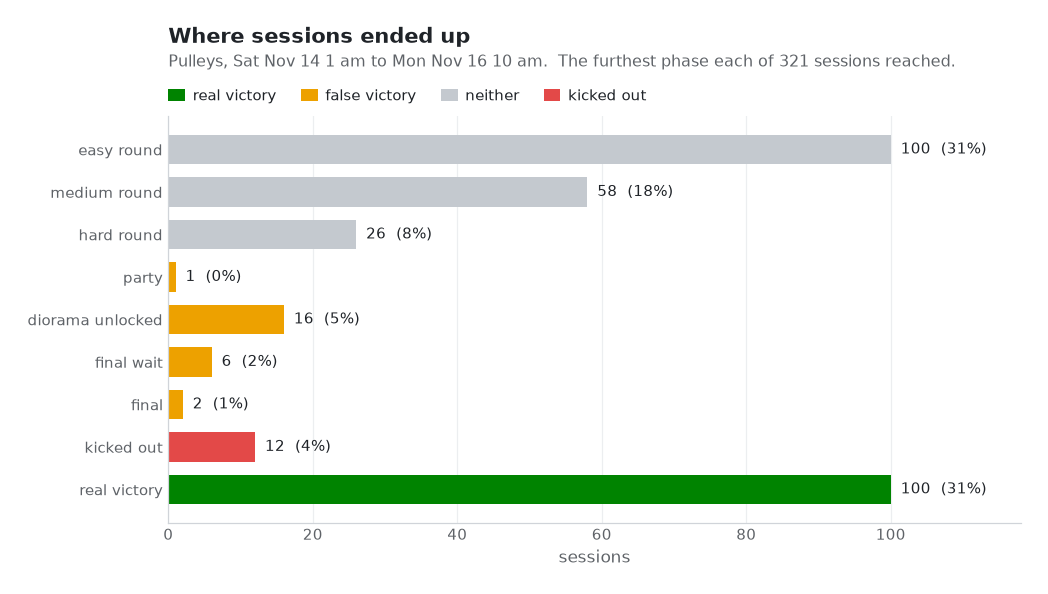

In [12]:
counts = df["outcome"].value_counts().reindex(order).fillna(0).astype(int)

fig, ax = plt.subplots(figsize=(10, 4.8))
y = np.arange(len(counts))
ax.barh(y, counts, height=0.7, color=[OUTCOME_COLOR[o] for o in counts.index])
ax.set_yticks(y, [o.replace("_", " ") for o in counts.index])
ax.invert_yaxis()
for i, k in enumerate(counts):
    ax.text(k, i, f"  {k}  ({k / len(df):.0%})", va="center", fontsize=10, color=INK)
ax.grid(axis="y", visible=False)
ax.grid(axis="x")
ax.set_xlim(0, counts.max() * 1.18)
ax.set_xlabel("sessions")
header(ax, "Where sessions ended up", f"{SPAN}.  The furthest phase each of {len(df)} sessions reached.",
       ([*TIER_LEGEND[0], swatch(KICKOUT_COLOR)], [*TIER_LEGEND[1], "kicked out"]))
save(fig, "09_furthest_phase")

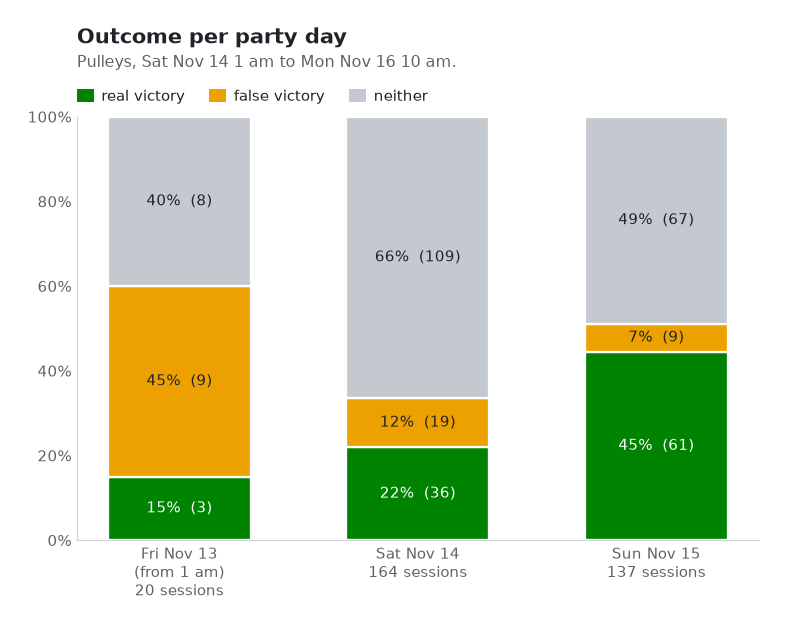

In [13]:
daily = pd.crosstab(df["day"], df["tier"]).reindex(columns=TIERS, fill_value=0)
share = daily.div(daily.sum(axis=1), axis=0) * 100
x = np.arange(len(daily))

fig, ax = plt.subplots(figsize=(8, 5))
bottom = np.zeros(len(daily))
for t in TIERS:
    ax.bar(x, share[t], bottom=bottom, width=0.6, color=TIER_COLOR[t], ec="white", lw=1.5)
    for i, (pct, k) in enumerate(zip(share[t], daily[t])):
        if pct >= 6:
            ax.text(i, bottom[i] + pct / 2, f"{pct:.0f}%  ({k})", ha="center", va="center", fontsize=10,
                    color="white" if t == "real victory" else INK)
    bottom += share[t].values
ax.set_xticks(x, [f"{DAY_LABEL[d]}\n{n} sessions" for d, n in zip(daily.index, daily.sum(axis=1))])
ax.set_ylim(0, 100)
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0f}%")
ax.grid(False)
header(ax, "Outcome per party day", SPAN + ".", TIER_LEGEND)
save(fig, "10_outcome_per_day")

In [14]:
# Many sessions are one stray pull that times out in easy_round. Leaving those out:
MIN_PULLS = 5
serious = df[df["pulls"] >= MIN_PULLS]
print(f"sessions with at least {MIN_PULLS} pulls: {len(serious)} of {len(df)}; "
      f"false victory {serious['game1'].sum()} ({serious['game1'].mean():.0%}), "
      f"real victory {serious['victory'].sum()} ({serious['victory'].mean():.0%})")
d = serious.groupby("day").agg(sessions=("n", "size"), game1=("game1", "sum"), victory=("victory", "sum"))
d.assign(game1_rate=(d["game1"] / d["sessions"]).round(2),
         victory_rate=(d["victory"] / d["sessions"]).round(2),
         # of those who reached false victory, how many went on to the real one
         victory_given_game1=(d["victory"] / d["game1"]).round(2)
         ).rename(index=lambda d: DAY_LABEL[d].replace("\n", " "))

sessions with at least 5 pulls: 283 of 321; false victory 130 (46%), real victory 100 (35%)


,sessions,game1,victory,game1_rate,victory_rate,victory_given_game1
day,,,,,,
Fri Nov 13 (from 1 am),17,10,3,0.59,0.18,0.30
Sat Nov 14,148,52,36,0.35,0.24,0.69
Sun Nov 15,118,68,61,0.58,0.52,0.90


In [15]:
print("PNGs for Slack:")
for p in sorted(PLOTS.glob("*.png")):
    print(" ", p)

PNGs for Slack:
  /Users/sam/git_repos/pulleys/field_logs/20261121-203050/plots/01_timeline.png
  /Users/sam/git_repos/pulleys/field_logs/20261121-203050/plots/02_sessions_per_hour.png
  /Users/sam/git_repos/pulleys/field_logs/20261121-203050/plots/03_success_by_hour.png
  /Users/sam/git_repos/pulleys/field_logs/20261121-203050/plots/04_heatmap.png
  /Users/sam/git_repos/pulleys/field_logs/20261121-203050/plots/05_session_length.png
  /Users/sam/git_repos/pulleys/field_logs/20261121-203050/plots/06_time_to_win.png
  /Users/sam/git_repos/pulleys/field_logs/20261121-203050/plots/07_length_by_phase.png
  /Users/sam/git_repos/pulleys/field_logs/20261121-203050/plots/08_length_vs_time.png
  /Users/sam/git_repos/pulleys/field_logs/20261121-203050/plots/09_furthest_phase.png
  /Users/sam/git_repos/pulleys/field_logs/20261121-203050/plots/10_outcome_per_day.png
